**Tópicos Selectos en Aprendizaje Maquinal - TP N°1: Algoritmos para Reconocimiento de Patrones**

**Estanislao Claucich**

### Ejercicio 1: Introducción y repaso de probabilidad y teoría de la información

Escriba un programa para generar números aleatorios $x$ con una función de densidad de probabilidad ($fdp$) gaussiana $\mathcal{N}(\mu,\Sigma)$ en $d$ dimensiones:

1. Para cada uno de los siguientes casos: i) $fdp$ gaussiana unidimensional; ii) $fdp$ gaussiana bidimensional no correlacionada y iii) $fdp$ gaussiana bidimensional correlacionada,  
    a) Genere un conjunto de números aleatorios con esa $fdp$.  
    b) Estime la $fdp$ experimental mediante un histograma normalizado.  
    c) Compare numéricamente el teorema mediante un histograma normalizado.  

2. Compruebe numéricamente el teorema del límite central mediante la suma de números aleatorios con distribución uniforme.  

3. Estime numéricamente y compare con el valor teórico, la entropía de una variable aleatoria con distribución: i) laplaciana; ii) gaussiana y iii) uniforme.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, multivariate_normal, laplace, uniform

rng = np.random.default_rng(42)

Un vector aleatorio $\mathbf{x}\in\mathbb{R}^d$ tiene distribución $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$ si su fdp es

$$
p(\mathbf{x}) = \frac{1}{(2\pi)^{d/2}\,|\boldsymbol{\Sigma}|^{1/2}}
\exp\!\left[-\tfrac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})\right]
$$

donde

- $\boldsymbol{\mu} = E[\mathbf{x}]$ es el vector de medias (centro de la distribución).
- $\boldsymbol{\Sigma} = E[(\mathbf{x}-\boldsymbol{\mu})(\mathbf{x}-\boldsymbol{\mu})^\top]$ es la matriz de covarianza, simétrica y definida positiva. Su diagonal contiene las varianzas $\sigma_i^2$ y los elementos fuera de la diagonal las covarianzas $\sigma_{ij}$.

En el caso unidimensional se reduce a $p(x)=\frac{1}{\sqrt{2\pi}\sigma}e^{-(x-\mu)^2/2\sigma^2}$.

Las curvas de nivel de $p(\mathbf{x})$ son los conjuntos donde $(\mathbf{x}-\boldsymbol{\mu})^\top\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})$ es constante, es decir, elipses (elipsoides en $d>2$) centradas en $\boldsymbol{\mu}$. Si descomponemos $\boldsymbol{\Sigma}=\mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^\top$:

- los autovectores (columnas de $\mathbf{V}$) dan la orientación de los ejes de la elipse;
- los autovalores $\lambda_i$ dan la varianza a lo largo de cada eje.

### 1. fdp

La función genera $N$ muestras de $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$ en $d$ dimensiones aplicando $\mathbf{x}=\boldsymbol{\mu}+\mathbf{L}\mathbf{z}$. Cada fila del resultado es una muestra. Como las muestras se guardan por filas, la transformación se escribe $\mathbf{X} = \mathbf{Z}\mathbf{L}^\top + \boldsymbol{\mu}$.

In [5]:
## Genera N muestras de N(mu, Sigma) en d dimensiones. Devuelve un array (N, d).
def gaussiana_nd(mu, Sigma, N, rng):
    mu = np.atleast_1d(mu).astype(float)
    Sigma = np.atleast_2d(Sigma).astype(float)
    d = mu.size

    L = np.linalg.cholesky(Sigma)         
    Z = rng.standard_normal((N, d))
    return mu + Z @ L.T

Para el caso de **gaussiana unidimensional**, se toma $\mu=0$ y $\sigma^2=1$, es decir $d=1$ y $\boldsymbol{\Sigma}=[\sigma^2]$.

In [ ]:
mu_1d, sigma_1d = 0.0, 1.0

Ns = [100, 1000, 10000, 100000]
muestras_1d = {N: gaussiana_nd(mu_1d, [[sigma_1d**2]], N, rng).ravel() for N in Ns}

print(f"{'N':>8} | {'media':>8} | {'desvío':>8}")
for N, x in muestras_1d.items():
    print(f"{N:>8} | {x.mean():8.4f} | {x.std(ddof=1):8.4f}")
print(f"{'teórico':>8} | {mu_1d:8.4f} | {sigma_1d:8.4f}")

       N |    media |   desvío
     100 |  -0.0503 |   0.7767
    1000 |  -0.0186 |   1.0009
   10000 |  -0.0069 |   1.0090
  100000 |  -0.0040 |   1.0033
 teórico |   0.0000 |   1.0000


Se estima la fdp con un histograma normalizado, comparando con la teórica $\mathcal{N}(0,1)$.

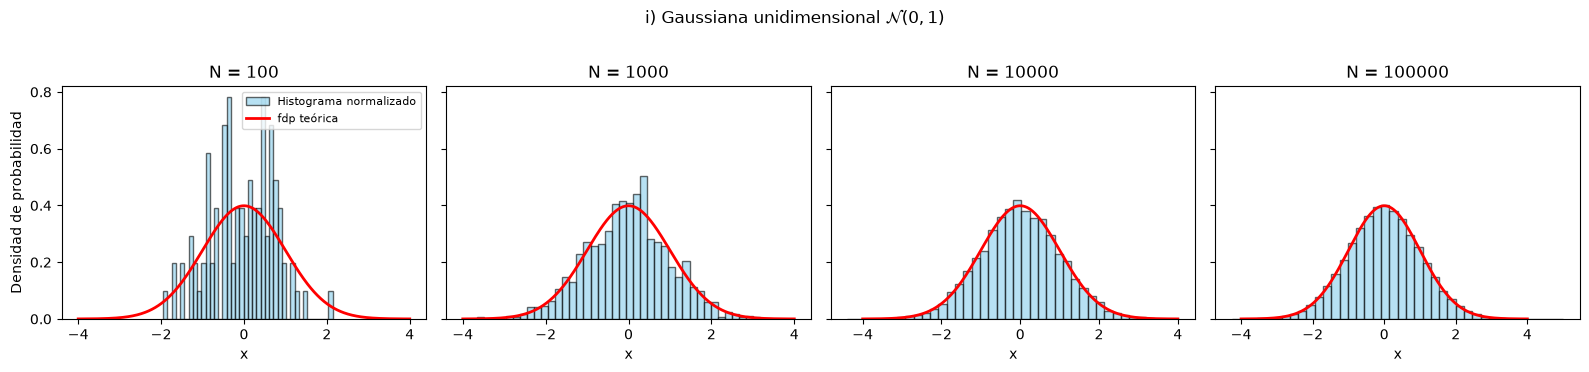

In [7]:
x_axis = np.linspace(mu_1d - 4*sigma_1d, mu_1d + 4*sigma_1d, 500)
pdf_teorica_1d = norm.pdf(x_axis, mu_1d, sigma_1d)

fig, axes = plt.subplots(1, len(Ns), figsize=(16, 3.6), sharey=True)
for ax, (N, x) in zip(axes, muestras_1d.items()):
    ax.hist(x, bins=40, density=True, alpha=0.6, color="skyblue", edgecolor="black",
            label="Histograma normalizado")
    ax.plot(x_axis, pdf_teorica_1d, "r-", lw=2, label="fdp teórica")
    ax.set_title(f"N = {N}")
    ax.set_xlabel("x")
axes[0].set_ylabel("Densidad de probabilidad")
axes[0].legend(fontsize=8)
fig.suptitle("i) Gaussiana unidimensional $\\mathcal{N}(0,1)$", y=1.02)
plt.tight_layout()
plt.show()

*A medida que $N$ crece, el histograma converge a la fdp teórica y la media y el desvío muestrales se acercan a $\mu$ y $\sigma$. Esto muestra que la calidad de una estimación de la fdp depende de la cantidad de datos disponibles.*

Para el caso de **gaussiana bidimensional**, para aislar el efecto de la correlación se usan dos matrices de covarianza con las mismas varianzas marginales ($\sigma_1^2=2$, $\sigma_2^2=1$) y se cambia únicamente la covarianza entre variables. Ambos casos comparten el vector de medias $\boldsymbol{\mu}=(1,\,-1)^\top$.

- **ii) No correlacionada:** $\boldsymbol{\Sigma}=\begin{pmatrix}2 & 0\\ 0 & 1\end{pmatrix}$
- **iii) Correlacionada:** $\boldsymbol{\Sigma}=\begin{pmatrix}2 & 1.2\\ 1.2 & 1\end{pmatrix}$, con coeficiente de correlación $\rho=\dfrac{\sigma_{12}}{\sigma_1\sigma_2}=\dfrac{1.2}{\sqrt{2}\cdot 1}\approx 0.85$.

In [8]:
def elipse_sigma(mu, Sigma, k, n=200):
    lam, V = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2*np.pi, n)
    circulo = np.vstack([np.cos(t), np.sin(t)]) # circunferencia unitaria
    return (mu[:, None] + k * V @ (np.sqrt(lam)[:, None] * circulo)).T


def gaussiana_2d(mu, Sigma, N, titulo, rng):
    mu = np.asarray(mu, float)
    Sigma = np.asarray(Sigma, float)

    # a) generar muestras
    data = gaussiana_nd(mu, Sigma, N, rng)

    # Parámetros teóricos vs. muestrales
    lam, V = np.linalg.eigh(Sigma)
    eje_mayor = V[:, np.argmax(lam)]
    angulo = np.degrees(np.arctan2(eje_mayor[1], eje_mayor[0])) % 180
    print(titulo)
    print("  media teórica  :", mu, "| muestral:", data.mean(axis=0).round(3))
    print("  Sigma teórica  :", Sigma.tolist())
    print("  Sigma muestral :", np.cov(data.T).round(3).tolist())
    print("  autovalores    :", lam.round(3), f"| ángulo del eje mayor: {angulo:.1f}°")



    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

    ax1.scatter(data[:, 0], data[:, 1], s=3, alpha=0.3, color="steelblue")
    for k, ls in zip([1, 2, 3], ["-", "--", ":"]):
        e = elipse_sigma(mu, Sigma, k)
        ax1.plot(e[:, 0], e[:, 1], "r", ls=ls, lw=1.5, label=f"{k}σ")
    ax1.plot(*mu, "k+", ms=12, mew=2)
    ax1.set_title("a) Muestras y elipses de nivel")
    ax1.legend()

    h = ax2.hist2d(data[:, 0], data[:, 1], bins=50, density=True, cmap="Blues")
    fig.colorbar(h[3], ax=ax2, label="Densidad empírica")
    xg, yg = np.mgrid[mu[0]-4.5:mu[0]+4.5:.05, mu[1]-4.5:mu[1]+4.5:.05]
    pdf = multivariate_normal(mu, Sigma).pdf(np.dstack((xg, yg)))
    cs = ax2.contour(xg, yg, pdf, colors="red", linewidths=1.3)
    ax2.clabel(cs, inline=True, fontsize=8, fmt="%.2f")
    ax2.set_title("b) Histograma 2D normalizado  +  c) fdp teórica (contornos)")

    for ax in (ax1, ax2):
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
        ax.set_xlim(mu[0]-4.5, mu[0]+4.5); ax.set_ylim(mu[1]-4.5, mu[1]+4.5)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    return data

#### Caso ii) No correlacionada

ii) Gaussiana 2D no correlacionada
  media teórica  : [ 1. -1.] | muestral: [ 1.009 -1.007]
  Sigma teórica  : [[2.0, 0.0], [0.0, 1.0]]
  Sigma muestral : [[2.01, -0.029], [-0.029, 1.016]]
  autovalores    : [1. 2.] | ángulo del eje mayor: 0.0°


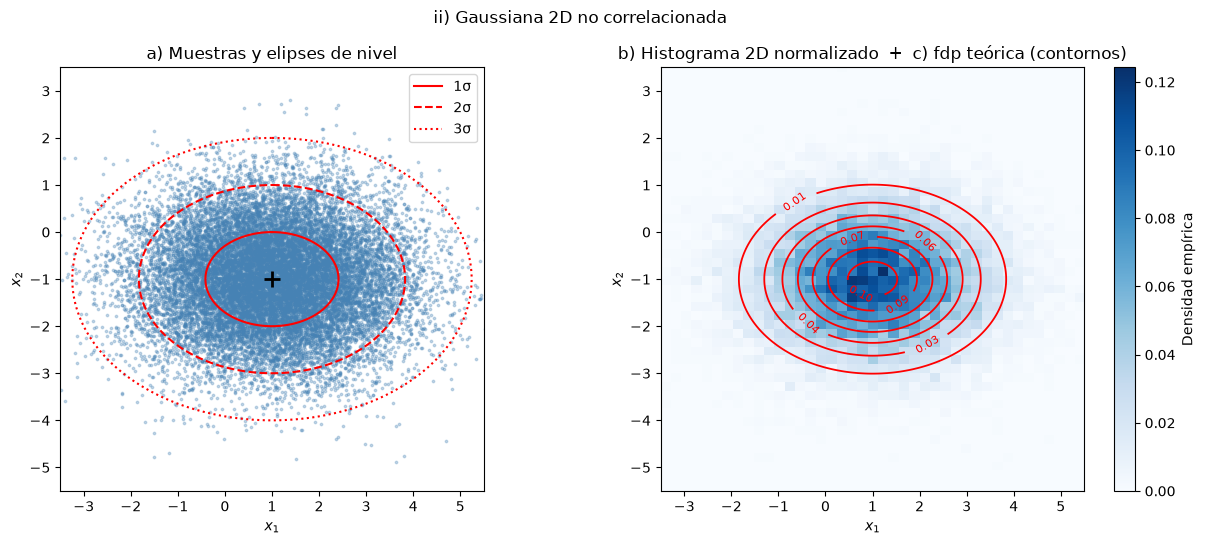

In [ ]:
mu_2d = [1.0, -1.0]
Sigma_no_corr = [[2.0, 0.0],
                 [0.0, 1.0]]

data_no_corr = gaussiana_2d(mu_2d, Sigma_no_corr, 20000, "ii) Gaussiana 2D no correlacionada", rng)

Como $\boldsymbol{\Sigma}$ es diagonal, sus autovectores son los ejes coordenados. Las elipses quedan alineadas con $x_1$ y $x_2$ (ángulo $0°$) y están más estiradas en $x_1$ porque $\sigma_1^2>\sigma_2^2$. Si $\sigma_1^2=\sigma_2^2$, serían circunferencias.

#### Caso iii) Correlacionada

iii) Gaussiana 2D correlacionada
  media teórica  : [ 1. -1.] | muestral: [ 1.004 -0.989]
  Sigma teórica  : [[2.0, 1.2], [1.2, 1.0]]
  Sigma muestral : [[1.983, 1.199], [1.199, 1.008]]
  autovalores    : [0.2 2.8] | ángulo del eje mayor: 33.7°


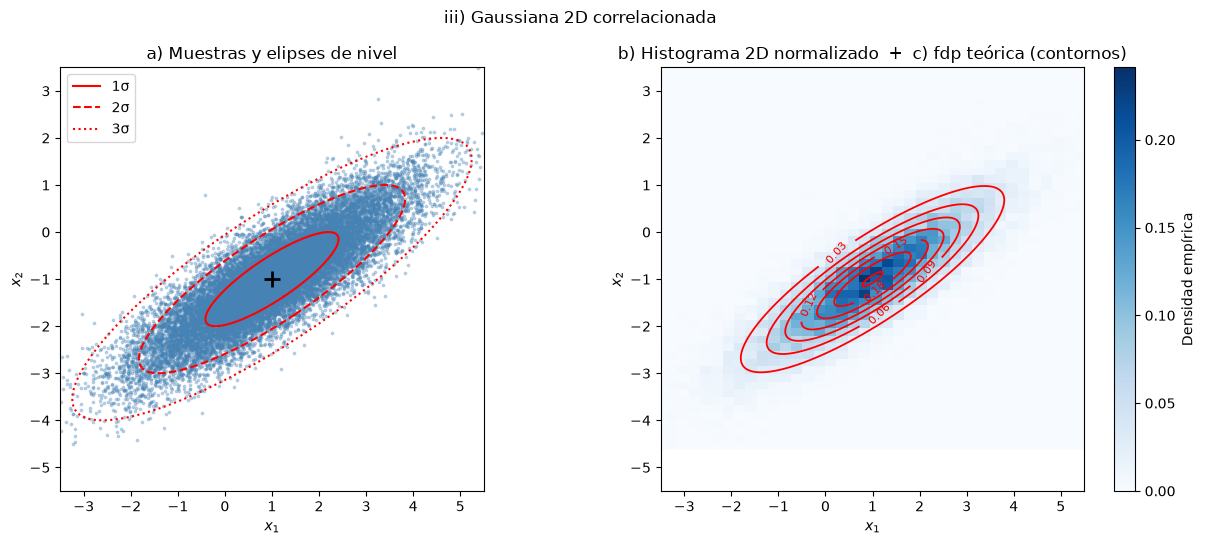

In [ ]:
Sigma_corr = [[2.0, 1.2],
              [1.2, 1.0]]

data_corr = gaussiana_2d(mu_2d, Sigma_corr, 20000, "iii) Gaussiana 2D correlacionada", rng)

*Con las mismas varianzas marginales, la covarianza positiva $\sigma_{12}=1.2$ se traduce en una rotación de las elipses.*

### 2. Teorema del límite central

Sean $X_1,\dots,X_K$ variables aleatorias independientes e idénticamente distribuidas con media $\mu$ y varianza $\sigma^2$ finitas. Entonces la suma $S_K=\sum_{i=1}^{K}X_i$ cumple

$$
\frac{S_K-K\mu}{\sigma\sqrt{K}}\;\xrightarrow[K\to\infty]{d}\;\mathcal{N}(0,1),
$$

es decir, para $K$ grande $S_K\approx\mathcal{N}(K\mu,\,K\sigma^2)$, sin importar la distribución original de las $X_i$.

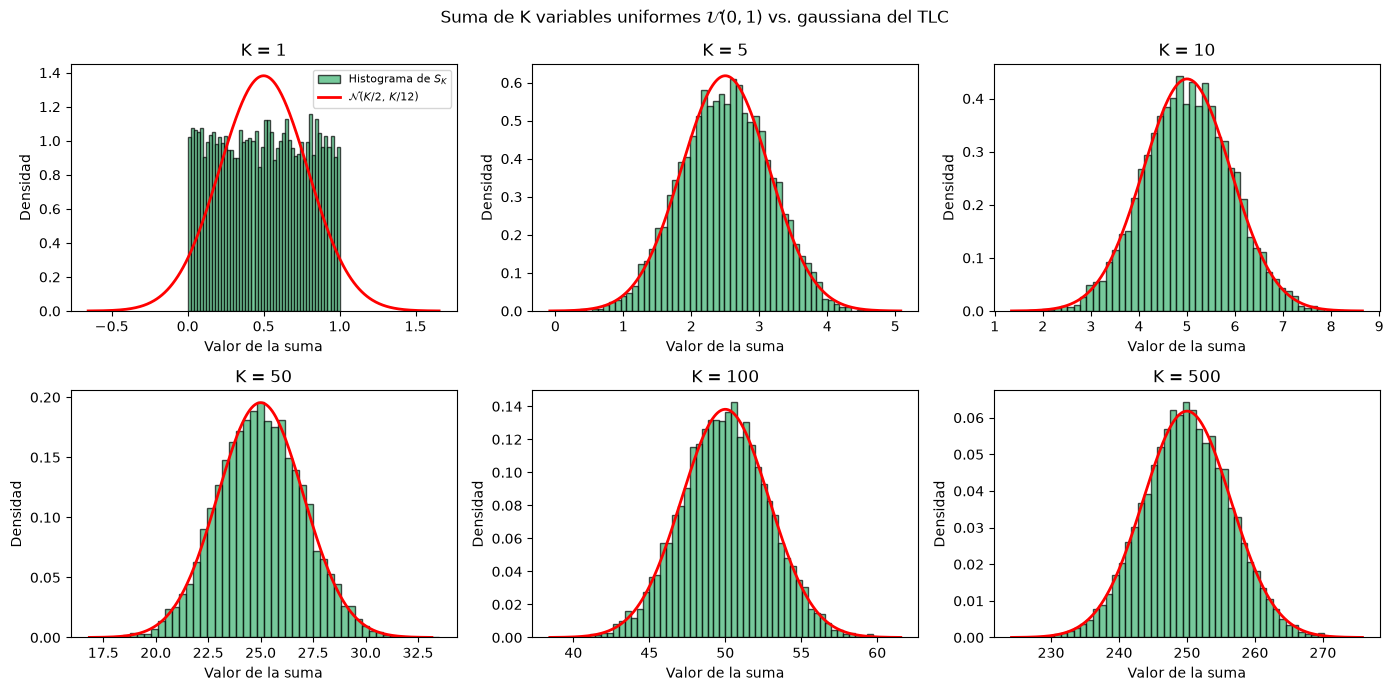

In [12]:
N_tlc = 10000
K_graf = [1, 5, 10, 50, 100, 500]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, K in zip(axes.ravel(), K_graf):
    S = rng.uniform(0, 1, (N_tlc, K)).sum(axis=1)

    mu_K, sigma_K = K/2, np.sqrt(K/12)
    xs = np.linspace(mu_K - 4*sigma_K, mu_K + 4*sigma_K, 400)

    ax.hist(S, bins=50, density=True, color="mediumseagreen", edgecolor="black", alpha=0.7,
            label="Histograma de $S_K$")
    ax.plot(xs, norm.pdf(xs, mu_K, sigma_K), "r-", lw=2, label=r"$\mathcal{N}(K/2,\,K/12)$")
    ax.set_title(f"K = {K}")
    ax.set_xlabel("Valor de la suma")
    ax.set_ylabel("Densidad")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Suma de K variables uniformes $\\mathcal{U}(0,1)$ vs. gaussiana del TLC")
plt.tight_layout()
plt.show()

Verificamos numéricamente lo anterior:

In [13]:
K_tabla = [1, 2, 5, 10, 20, 40, 80, 100, 200]

print(f"{'K':>5} | {'curtosis exc.':>13} | {'teórica -1.2/K':>14} | {'KS vs N(K/2,K/12)':>18}")
print("-" * 62)
for K in K_tabla:
    S = rng.uniform(0, 1, (N_tlc, K)).sum(axis=1)
    curt = stats.kurtosis(S)                                          # exceso de curtosis (Fisher)
    ks = stats.kstest(S, norm(K/2, np.sqrt(K/12)).cdf).statistic  # distancia de Kolmogorov-Smirnov
    print(f"{K:>5} | {curt:13.3f} | {-1.2/K:14.3f} | {ks:18.4f}")

    K | curtosis exc. | teórica -1.2/K |  KS vs N(K/2,K/12)
--------------------------------------------------------------
    1 |        -1.191 |         -1.200 |             0.0608
    2 |        -0.609 |         -0.600 |             0.0183
    5 |        -0.253 |         -0.240 |             0.0105
   10 |        -0.098 |         -0.120 |             0.0082
   20 |        -0.012 |         -0.060 |             0.0087
   40 |        -0.066 |         -0.030 |             0.0096
   80 |        -0.039 |         -0.015 |             0.0060
  100 |        -0.051 |         -0.012 |             0.0095
  200 |         0.055 |         -0.006 |             0.0076


*La curtosis en exceso tiende a $0$ (valor de una gaussiana). El TLC justifica por qué el ruido de medición, o el error agregado en muchos conjuntos de datos reales, suele modelarse como gaussiano: es el resultado de la suma de numerosos efectos pequeños e independientes. Esto también explica el rol central que tiene la distribución gaussiana en el reconocimiento de patrones.*

### 3. Entropía diferencial

La **entropía diferencial** de una variable aleatoria continua con fdp $p(x)$ mide la incertidumbre asociada a ella:

$$
H(x) = -\int p(x)\,\ln p(x)\,dx = E\big[-\ln p(x)\big].
$$

Para las tres distribuciones (laplaciana, gaussiana y uniforme) existen expresiones cerradas:

| Distribución | fdp | Entropía $H$ |
|:--|:--|:--|
| Gaussiana $\mathcal{N}(\mu,\sigma^2)$ | $\frac{1}{\sqrt{2\pi}\sigma}e^{-(x-\mu)^2/2\sigma^2}$ | $\tfrac12\ln(2\pi e\,\sigma^2)$ |
| Laplaciana $(\mu,b)$ | $\frac{1}{2b}e^{-\lvert x-\mu\rvert/b}$ | $1+\ln(2b)$ |
| Uniforme $\mathcal{U}(a,c)$ | $\frac{1}{c-a}$ en $[a,c]$ | $\ln(c-a)$ |

Como $H$ es una esperanza, la ley de los grandes números permite aproximarla con el promedio muestral. Dadas $T$ muestras $x_t\sim p(x)$ independientes:

$$
H(x) = E[-\ln p(x)]\;\approx\;-\frac{1}{T}\sum_{t=1}^{T}\ln p(x_t).
$$

A medida que $T\to\infty$ el estimador converge al valor teórico, con un error típico que decae como $1/\sqrt{T}$.

Se eligen los siguientes parámetros:

- Laplaciana: $\mu=0$, $b=1$ (varianza $2b^2=2$)
- Gaussiana: $\mu=0$, $\sigma=1$ (varianza $1$)
- Uniforme: $\mathcal{U}(-2,2)$ (varianza $4^2/12\approx1.33$)

In [ ]:
dist_laplace = laplace(loc=0.0, scale=1.0)
dist_norm    = norm(loc=0.0, scale=1.0)
dist_unif    = uniform(loc=-2.0, scale=4.0)

# Fórmulas cerradas
H_laplace_formula = 1 + np.log(2 * 1.0)
H_norm_formula    = 0.5 * np.log(2 * np.pi * np.e * 1.0**2)
H_unif_formula    = np.log(2.0 - (-2.0))

# Valores teóricos
H_teo = {"Laplaciana": dist_laplace.entropy(),
         "Gaussiana":  dist_norm.entropy(),
         "Uniforme":   dist_unif.entropy()}
H_formula = {"Laplaciana": H_laplace_formula,
             "Gaussiana":  H_norm_formula,
             "Uniforme":   H_unif_formula}

print(f"{'Distribución':<12} | {'fórmula':>14} | {'scipy':>12}")
for nombre in H_teo:
    print(f"{nombre:<12} | {H_formula[nombre]:14.4f} | {H_teo[nombre]:12.4f}")

Distribución |        fórmula |        scipy
Laplaciana   |         1.6931 |       1.6931
Gaussiana    |         1.4189 |       1.4189
Uniforme     |         1.3863 |       1.3863


Para estimar numéricamente, se generan $T=10^5$ muestras de cada distribución y se calcula el estimador $-\frac1t\sum_{i=1}^{t}\ln p(x_i)$ para $t=1,\dots,T$, para ver cómo evoluciona la estimación al aumentar la cantidad de datos.

In [16]:
T = 100000
dists = {"Laplaciana": (dist_laplace, "blue"),
         "Gaussiana":  (dist_norm,    "red"),
         "Uniforme":   (dist_unif,    "green")}

muestras = {n: d.rvs(size=T, random_state=rng) for n, (d, _) in dists.items()}


def entropia_acumulada(x, dist):
    sorpresa = -np.log(dist.pdf(x)) # -ln p(x_t)
    return np.cumsum(sorpresa) / np.arange(1, len(x) + 1)


trayectorias = {n: entropia_acumulada(muestras[n], d) for n, (d, _) in dists.items()}

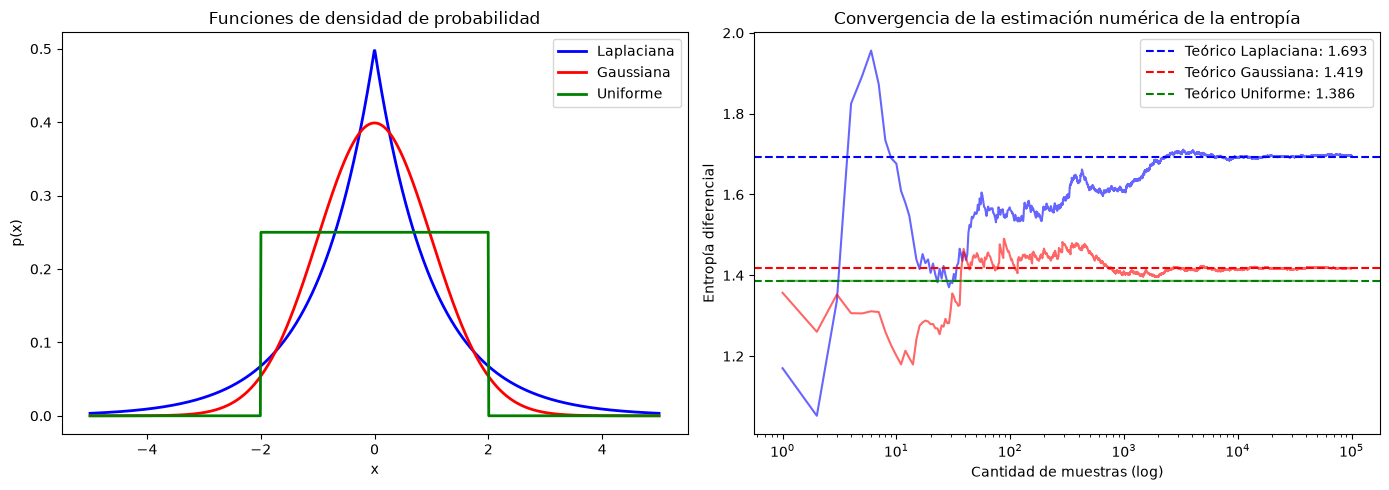

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

xs = np.linspace(-5, 5, 1000)
for n, (d, c) in dists.items():
    ax1.plot(xs, d.pdf(xs), color=c, lw=2, label=n)
ax1.set_title("Funciones de densidad de probabilidad")
ax1.set_xlabel("x"); ax1.set_ylabel("p(x)")
ax1.legend()

t = np.arange(1, T + 1)
for n, (d, c) in dists.items():
    ax2.plot(t, trayectorias[n], color=c, alpha=0.6)
    ax2.axhline(H_teo[n], color=c, ls="--", label=f"Teórico {n}: {H_teo[n]:.3f}")
ax2.set_xscale("log")
ax2.set_title("Convergencia de la estimación numérica de la entropía")
ax2.set_xlabel("Cantidad de muestras (log)")
ax2.set_ylabel("Entropía diferencial")
ax2.legend()

plt.tight_layout()
plt.show()

Estimación para distintos $T$ junto con el error estándar del estimador, calculado como $\hat\sigma/\sqrt{T}$, donde $\hat\sigma$ es el desvío muestral de $-\ln p(x_t)$.

In [19]:
T_vals = [10, 100, 1000, 10000, 100000]

print(f"{'Distribución':<12} | " + " | ".join(f"T={tv:>6}" for tv in T_vals) + " |  teórico | error est. (T=1e5)")
print("-" * 100)
for n, (d, _) in dists.items():
    est = [trayectorias[n][tv - 1] for tv in T_vals]
    se = (-np.log(d.pdf(muestras[n]))).std(ddof=1) / np.sqrt(T)
    print(f"{n:<12} | " + " | ".join(f"{e:8.4f}" for e in est) + f" | {H_teo[n]:8.4f} | {se:.5f}")

Distribución | T=    10 | T=   100 | T=  1000 | T= 10000 | T=100000 |  teórico | error est. (T=1e5)
----------------------------------------------------------------------------------------------------
Laplaciana   |   1.6763 |   1.5632 |   1.6096 |   1.6930 |   1.6960 |   1.6931 | 0.00318
Gaussiana    |   1.2011 |   1.4470 |   1.4085 |   1.4135 |   1.4179 |   1.4189 | 0.00224
Uniforme     |   1.3863 |   1.3863 |   1.3863 |   1.3863 |   1.3863 |   1.3863 | 0.00000


En la comparación anterior, la laplaciana resulta ser la de mayor entropía, seguida por la gaussiana y la uniforme. Pero las tres distribuciones tienen varianzas distintas ($2$, $1$ y $1.33$ respectivamente), y la entropía diferencial crece con la dispersión.

Si comparamos las tres distribuciones con igual varianza $\sigma^2=1:

- Gaussiana: $\sigma=1$.
- Laplaciana: $2b^2=1\Rightarrow b=1/\sqrt2$.
- Uniforme: $\frac{(c-a)^2}{12}=1\Rightarrow c-a=2\sqrt3$.

In [20]:
dists_iguales = {
    "Gaussiana":  norm(loc=0, scale=1.0),
    "Laplaciana": laplace(loc=0, scale=1/np.sqrt(2)),
    "Uniforme":   uniform(loc=-np.sqrt(3), scale=2*np.sqrt(3)),
}

print(f"{'Distribución':<12} | {'varianza':>8} | {'H teórica':>9} | {'H estimada (T=1e5)':>18}")
for n, d in dists_iguales.items():
    x = d.rvs(size=T, random_state=rng)
    H_est = -np.mean(np.log(d.pdf(x)))
    print(f"{n:<12} | {d.var():8.3f} | {d.entropy():9.4f} | {H_est:18.4f}")

Distribución | varianza | H teórica | H estimada (T=1e5)
Gaussiana    |    1.000 |    1.4189 |             1.4203
Laplaciana   |    1.000 |    1.3466 |             1.3438
Uniforme     |    1.000 |    1.2425 |             1.2425


Con igual varianza Gaussiana > Laplaciana > Uniforme. La gaussiana es la que más incertidumbre tiene para una dispersión dada, la laplaciana (más concentrada en torno a la media y con colas más largas) tiene menos, y la uniforme, que descarta por completo los valores fuera de su soporte, es la de menor entropía.

*La propiedad de máxima entropía de la gaussiana justifica usarla como el modelo "menos comprometido" cuando sólo se conocen la media y la varianza de los datos.*

### Conclusiones

1. Un vector $\mathcal{N}(\boldsymbol{\mu},\boldsymbol{\Sigma})$ se genera como $\boldsymbol{\mu}+\mathbf{L}\mathbf{z}$ con $\boldsymbol{\Sigma}=\mathbf{L}\mathbf{L}^\top$ y $\mathbf{z}\sim\mathcal{N}(\mathbf{0},\mathbf{I})$. El histograma normalizado converge a la fdp teórica al aumentar $N$. La matriz $\boldsymbol{\Sigma}$ determina la forma de la densidad, diagonal $\Rightarrow$ elipses alineadas con los ejes; términos fuera de la diagonal $\Rightarrow$ elipses rotadas según los autovectores de $\boldsymbol{\Sigma}$.
2. La suma de $K$ uniformes pasa de una densidad plana ($K=1$) a una triangular ($K=2$) y converge rápidamente a la gaussiana $\mathcal{N}(K/2,K/12)$ (TLC).
3.  La entropía diferencial converge al valor teórico con un error del orden de $1/\sqrt{T}$, y para pocas muestras es inestable. En el caso uniforme la estimación es exacta. Para una misma varianza la gaussiana es la de máxima entropía.